# UDAI 2026 · Cafe Revenue Forecasting — pipeline gọn

Dự đoán doanh thu ngày (triệu VND) của 44 cửa hàng Moc Coffee từ 01/01 đến 31/03/2026 (có Tết).

**Tiêu chí của cuộc thi** và cách notebook đáp ứng:

| Tiêu chí | Trong notebook |
|---|---|
| Chấm bằng **RMSLE** (thấp hơn là tốt hơn) | Học trên `log1p(revenue)` → tối ưu đúng RMSLE |
| Dự đoán ≥ 0, mỗi `id` của `test.csv` xuất hiện đúng 1 lần, 2 cột `id,revenue` | Hàm `save_submission` kiểm tra trước khi ghi |
| Validate trên **các tháng gần nhất**, không chia ngẫu nhiên | 4 fold theo quý 2025, mỗi fold chỉ học quá khứ |
| Notebook phải **tái tạo được cả 2 submission** đã chọn | Ghi `submission_1_ridge.csv` và `submission_2_blend.csv`, seed cố định |
| Dữ liệu bẩn: đơn vị, trùng, lỗi gõ, thiếu ngày, nhãn không thống nhất | Mục 2 liệt kê và sửa từng lỗi |

Mốc điểm private: starter ≈ 0.26 · tốt ≤ 0.20 · rất tốt ≤ 0.16 · xuất sắc ≤ 0.14.

**Chạy trên Kaggle:** Import Notebook → Add Input › Competitions › *UDAI 2026 · Cafe Revenue Forecasting* → Run All. Chỉ cần CPU, khoảng 3–4 phút.

## 1. Thư viện và dữ liệu

In [1]:
import glob
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'lines.linewidth': 2})

# Bộ Cafe được nhận diện qua stores.csv (bộ Churn không có file này); ưu tiên thư mục có test.csv.
hits = [Path(p).parent for p in glob.glob('/kaggle/input/**/stores.csv', recursive=True)
        + glob.glob('stores.csv') + glob.glob('cafe/stores.csv')]
if not hits:
    raise FileNotFoundError('Không thấy stores.csv. Trên Kaggle: Add Input › Competitions › UDAI 2026 · Cafe Revenue Forecasting')
DATA = sorted(hits, key=lambda p: not (p / 'test.csv').exists())[0]
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs_cafe')
OUT.mkdir(exist_ok=True)

train_raw = pd.read_csv(DATA / 'train.csv', parse_dates=['date'])
stores_raw = pd.read_csv(DATA / 'stores.csv')
weather_raw = pd.read_csv(DATA / 'weather.csv', parse_dates=['date'])
holidays = pd.read_csv(DATA / 'holidays.csv', parse_dates=['date'])
sample = pd.read_csv(DATA / 'sample_submission.csv')
test = pd.read_csv(DATA / 'test.csv', parse_dates=['date']) if (DATA / 'test.csv').exists() else None

print('Dữ liệu:', DATA.resolve(), '| Kết quả lưu ở:', OUT.resolve())
for name, df in [('train', train_raw), ('test', test), ('stores', stores_raw),
                 ('weather', weather_raw), ('holidays', holidays), ('sample', sample)]:
    if df is None:
        print(f'{name:9s} KHÔNG CÓ — cần test.csv của cuộc thi để tạo submission')
        continue
    span = f'{df.date.min().date()} → {df.date.max().date()}' if 'date' in df else ''
    print(f'{name:9s} {str(df.shape):12s} {span}')

Dữ liệu: C:\Users\Ngoc Hieu\Desktop\colabnhi\cafe | Kết quả lưu ở: C:\Users\Ngoc Hieu\Desktop\colabnhi\outputs_cafe
train     (26632, 4)   2024-01-01 → 2025-12-31
test      KHÔNG CÓ — cần test.csv của cuộc thi để tạo submission
stores    (45, 8)      
weather   (1593, 4)    2024-01-01 → 2026-03-31
holidays  (55, 3)      2024-01-01 → 2026-03-08
sample    (3869, 2)    


## 2. Kiểm tra chất lượng dữ liệu

Đếm từng loại lỗi trước khi sửa, để báo cáo có số liệu cụ thể. Bảng được lưu thành `data_quality.csv`.

In [2]:
dedup = train_raw.drop_duplicates()
weather_days = weather_raw.city.nunique() * len(pd.date_range(weather_raw.date.min(), weather_raw.date.max()))
quality = pd.Series({
    'train: dòng trùng hoàn toàn': train_raw.duplicated().sum(),
    'train: cùng (ngày, cửa hàng) nhưng khác doanh thu': dedup.duplicated(['date', 'store_id']).sum(),
    'train: doanh thu > 1000 (nhập theo nghìn VND)': (train_raw.revenue > 1000).sum(),
    'train: ngày đột biến > 4× trung vị cửa hàng': (dedup.revenue.where(dedup.revenue <= 1000, dedup.revenue / 1000)
                                                    > 4 * dedup.groupby('store_id').revenue.transform('median')).sum(),
    'stores: store_type viết hoa/thường lẫn lộn': stores_raw.store_type.nunique() - stores_raw.store_type.str.lower().nunique(),
    'stores: district viết kiểu Q.10 / Quan 3 / Quan 7': stores_raw.district.str.match(r'^(Q\.|Quan )').sum(),
    'stores: open_date dạng dd/mm/yyyy': stores_raw.open_date.str.contains('/').sum(),
    'stores: thiếu area_m2': stores_raw.area_m2.isna().sum(),
    'weather: nhiệt độ ghi theo °F (> 55)': (weather_raw.temp_c > 55).sum(),
    'weather: thiếu rain_mm': weather_raw.rain_mm.isna().sum(),
    'weather: thiếu cả ngày (thành phố × ngày)': weather_days - len(weather_raw),
    'holidays: ngày có 2 sự kiện': holidays.date.duplicated().sum(),
}, name='số lượng').astype(int)
display(quality.to_frame())
quality.to_csv(OUT / 'data_quality.csv')

units = train_raw[train_raw.revenue > 1000]
print('Doanh thu > 1000 nằm ở:', sorted(units.store_id.unique()),
      sorted(units.date.dt.strftime('%Y-%m').unique()))
last_day = dedup.groupby('store_id').date.max()
print('Cửa hàng ngừng báo cáo trước cuối 2025:', last_day[last_day < '2025-12-01'].to_dict())

,số lượng
train: dòng trùng hoàn toàn,132
"train: cùng (ngày, cửa hàng) nhưng khác doanh thu",0
train: doanh thu > 1000 (nhập theo nghìn VND),31
train: ngày đột biến > 4× trung vị cửa hàng,51
stores: store_type viết hoa/thường lẫn lộn,4
stores: district viết kiểu Q.10 / Quan 3 / Quan 7,6
stores: open_date dạng dd/mm/yyyy,15
stores: thiếu area_m2,2
weather: nhiệt độ ghi theo °F (> 55),22
weather: thiếu rain_mm,16


Doanh thu > 1000 nằm ở: ['S12'] ['2024-03']
Cửa hàng ngừng báo cáo trước cuối 2025: {'S02': Timestamp('2025-08-14 00:00:00')}


### Cách xử lý

- **Trùng hoàn toàn:** bỏ. Không có trường hợp cùng ngày/cửa hàng mà khác doanh thu.
- **Sai đơn vị:** S12 tháng 3/2024 có ~30 giá trị cỡ 29.000 trong khi các tháng xung quanh cỡ 25–31 → chia 1000.
- **Ngày đột biến (×8–×20):** rải rác, không gắn với lễ hay khuyến mãi nên không đoán trước được. Ta **không xoá**:
  Ridge dùng trọng số robust (mục 4) để các ngày này gần như không ảnh hưởng mô hình. Validation vẫn tính trên nhãn gốc.
- **stores:** chuẩn hoá chữ thường, gộp tên quận, đọc 2 định dạng ngày, `area_m2` thiếu → `seats × (diện tích/ghế trung vị)`.
- **weather:** đổi °F → °C, bổ sung ngày thiếu bằng nội suy theo thành phố, mưa thiếu → 0 (có cờ `weather_missing`).
- **holidays:** gộp về một dòng mỗi ngày bằng các cờ 0/1 để khi ghép không nhân bản dòng.
- **Ngày không có dòng** nghĩa là cửa hàng đóng/không báo cáo; `test.csv` chỉ chứa ngày cần dự đoán nên không cần tự tạo thêm.

In [3]:
train = train_raw.drop_duplicates().reset_index(drop=True)
assert not train.duplicated(['date', 'store_id']).any()
train.loc[train.revenue > 1000, 'revenue'] /= 1000
assert (train.revenue > 0).all()

stores = stores_raw.copy()
stores['store_type'] = stores.store_type.str.strip().str.lower()
stores['district'] = stores.district.str.strip().replace({'Q.10': 'District 10', 'Quan 3': 'District 3', 'Quan 7': 'District 7'})
stores['open_date'] = (pd.to_datetime(stores.open_date, format='%Y-%m-%d', errors='coerce')
                       .fillna(pd.to_datetime(stores.open_date, format='%d/%m/%Y', errors='coerce')))
stores['area_m2'] = stores.area_m2.fillna(stores.seats * (stores.area_m2 / stores.seats).median())
assert stores.open_date.notna().all() and stores.store_id.is_unique

weather = weather_raw.copy()
fahrenheit = weather.temp_c > 55
weather.loc[fahrenheit, 'temp_c'] = (weather.loc[fahrenheit, 'temp_c'] - 32) / 1.8
grid = pd.MultiIndex.from_product([weather.city.unique(), pd.date_range(weather.date.min(), weather.date.max())],
                                  names=['city', 'date'])
weather = weather.set_index(['city', 'date']).reindex(grid).reset_index()
weather['weather_missing'] = weather.temp_c.isna().astype(int)
weather['temp_c'] = weather.groupby('city').temp_c.transform(lambda s: s.interpolate(limit_direction='both'))
weather['rain_mm'] = weather.rain_mm.fillna(0).clip(lower=0)

EVENTS = {'new_year': "New Year's Day", 'valentine': "Valentine's Day", 'women_mar': "International Women's Day",
          'women_oct': "Vietnamese Women's Day", 'teachers': "Teachers' Day", 'xmas': 'Christmas',
          'national_day': 'National Day', 'hung_kings': 'Hung Kings', 'reunification': 'Reunification',
          'labour': 'Labour', 'kitchen_gods': 'Ong Cong'}
hol = pd.DataFrame({'date': holidays.date,
                    'national_other': (holidays.type.eq('national_holiday')
                                       & ~holidays.holiday_name.str.contains('Tet')).astype(int)})
for col, name in EVENTS.items():
    hol[col] = holidays.holiday_name.str.contains(name, regex=False).astype(int)
hol = hol.groupby('date', as_index=False).max()
TET = np.sort(holidays.loc[holidays.holiday_name.eq('Lunar New Year (Tet)'), 'date'].to_numpy())

train_clean = train.merge(stores[['store_id', 'city', 'store_type']], on='store_id', validate='many_to_one')
train_clean.to_csv(OUT / 'train_clean.csv', index=False)
print('train sau làm sạch:', train.shape, '| Tết:', [str(t)[:10] for t in TET])

train sau làm sạch: (26500, 4) | Tết: ['2024-02-10', '2025-01-29', '2026-02-17']


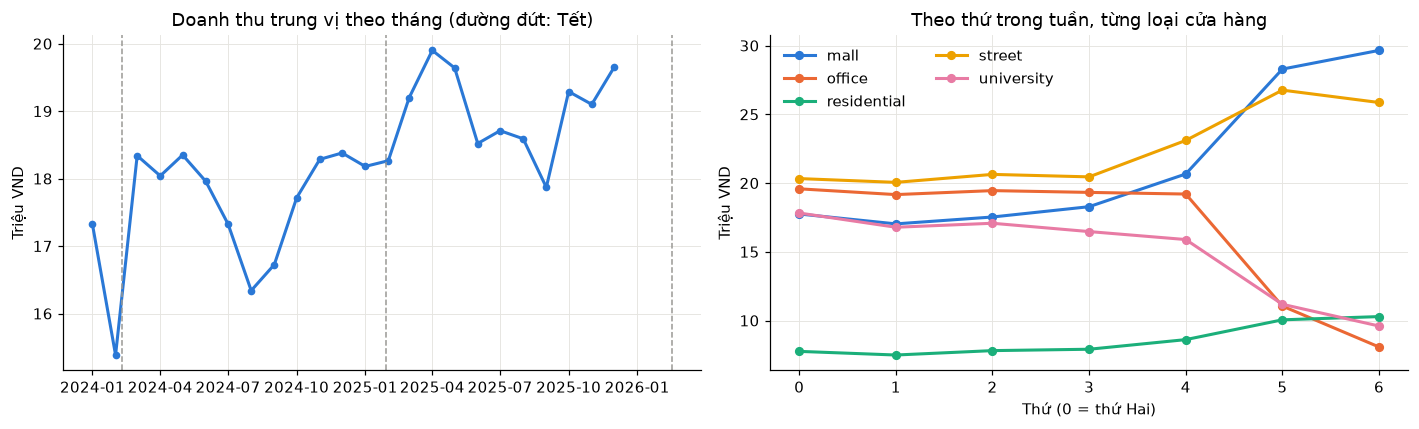

In [4]:
monthly = train.groupby(train.date.dt.to_period('M')).revenue.median()
weekday = (train_clean.assign(dow=train_clean.date.dt.day_of_week)
           .groupby(['dow', 'store_type']).revenue.median().unstack())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(monthly.index.to_timestamp(), monthly.values, color=COLORS[0], marker='o', markersize=4)
for tet in TET:
    axes[0].axvline(tet, color='#9a9994', linestyle='--', linewidth=1)
axes[0].set(title='Doanh thu trung vị theo tháng (đường đứt: Tết)', ylabel='Triệu VND')
for color, col in zip(COLORS, weekday.columns):
    axes[1].plot(weekday.index, weekday[col], color=color, marker='o', markersize=5, label=col)
axes[1].set(title='Theo thứ trong tuần, từng loại cửa hàng', xlabel='Thứ (0 = thứ Hai)', ylabel='Triệu VND')
axes[1].legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(OUT / 'data_overview.png', bbox_inches='tight')
plt.show()

## 3. Đặc trưng

Chỉ dùng thông tin **biết trước** ngày cần dự đoán: cửa hàng, lịch, lễ, thời tiết, khuyến mãi — không dùng doanh thu trễ (lag),
vì 3 tháng test không có doanh thu thật để làm lag.

- **Lịch:** thứ, tháng, sóng mùa vụ sin/cos, xu hướng `time_years`.
- **Tết:** số ngày tới Tết gần nhất. Lịch nghỉ chính thức dài khác nhau mỗi năm, nên dùng các khoảng cố định
  (trước Tết, lõi −2…+3, sau Tết) và mã ngày ±14 theo từng loại cửa hàng.
- **Cửa hàng:** mã cửa hàng, loại, quận, kích thước, độ tuổi (cửa hàng mới mở tăng dần doanh thu trong vài tháng đầu).
- **Tương tác** cho Ridge: loại cửa hàng × lịch/lễ/thời tiết, thành phố × thời tiết, cửa hàng × xu hướng.

In [5]:
def build_features(df):
    X = df[['date', 'store_id', 'is_promo']].merge(stores, on='store_id', how='left', validate='many_to_one')
    X = X.merge(weather, on=['date', 'city'], how='left', validate='many_to_one')
    X = X.merge(hol, on='date', how='left', validate='many_to_one')
    assert len(X) == len(df) and X.city.notna().all() and X.temp_c.notna().all()
    X[hol.columns[1:]] = X[hol.columns[1:]].fillna(0)
    d = X.date.dt
    X['dow'] = d.day_of_week.astype(str)
    X['month'] = d.month.astype(str)
    X['summer'] = d.month.isin([6, 7, 8]).astype(int)
    X['winter'] = d.month.isin([1, 2]).astype(int)
    X['time_years'] = (X.date - pd.Timestamp('2024-01-01')).dt.days / 365.25
    for k in [1, 2, 3]:
        X[f'sin_{k}'] = np.sin(2 * np.pi * k * (d.day_of_year - 1) / 365.25)
        X[f'cos_{k}'] = np.cos(2 * np.pi * k * (d.day_of_year - 1) / 365.25)
    age = (X.date - X.open_date).dt.days.clip(lower=0)
    for days in [14, 30, 60, 90, 180]:
        X[f'age_ramp_{days}'] = np.minimum(age / days, 1)
    for days in [3, 7, 14]:
        X[f'opening_{days}'] = (age < days).astype(int)
    X['log_seats'] = np.log1p(X.seats)
    X['log_area'] = np.log1p(X.area_m2)
    X['temp_scaled'] = (X.temp_c - 26) / 10
    X['temp_square'] = X.temp_scaled ** 2
    X['rain_scaled'] = X.rain_mm / 10
    X['log_rain'] = np.log1p(X.rain_mm)
    X['rain_heavy'] = (X.rain_mm >= 20).astype(int)
    offsets = (X.date.to_numpy()[:, None] - TET[None, :]) / np.timedelta64(1, 'D')
    tet = offsets[np.arange(len(X)), np.abs(offsets).argmin(axis=1)].astype(int)
    X['tet_offset'] = np.clip(tet, -45, 45)
    X['tet_holiday'] = ((tet >= -2) & (tet <= 3)).astype(int)
    X['tet_before'] = ((tet >= -14) & (tet < -3)).astype(int)
    X['tet_core'] = ((tet >= -3) & (tet <= 4)).astype(int)
    X['tet_after'] = ((tet >= 5) & (tet <= 14)).astype(int)
    X['national'] = np.maximum(X.national_other, X.tet_holiday)
    tet_day = np.where(np.abs(tet) <= 14, tet.astype(str), 'outside')
    X['type_dow'] = X.store_type + '_' + X.dow
    X['store_dow'] = X.store_id + '_' + X.dow
    X['type_month'] = X.store_type + '_' + X.month
    X['type_tet'] = X.store_type + '_' + tet_day
    return X


CATS = ['store_id', 'city', 'store_type', 'district', 'dow', 'month', 'type_dow', 'store_dow', 'type_month', 'type_tet']
NUMS = ['log_seats', 'log_area', 'has_parking', 'is_promo', 'time_years', 'temp_scaled', 'temp_square',
        'rain_scaled', 'log_rain', 'rain_heavy', 'national', 'tet_holiday', 'tet_before', 'tet_core', 'tet_after',
        'summer', 'winter', *EVENTS, *[f'{f}_{k}' for f in ['sin', 'cos'] for k in [1, 2, 3]],
        *[f'age_ramp_{d}' for d in [14, 30, 60, 90, 180]], 'opening_3', 'opening_7', 'opening_14']
BY_TYPE = ['is_promo', 'time_years', 'national', 'tet_holiday', 'tet_before', 'tet_core', 'tet_after',
           *[e for e in EVENTS if e != 'kitchen_gods'], 'summer', 'winter', 'rain_scaled', 'log_rain',
           'temp_scaled', 'temp_square', 'sin_1', 'cos_1', 'sin_2', 'cos_2', 'opening_3', 'opening_7']
BY_CITY = ['temp_scaled', 'rain_scaled', 'sin_1', 'cos_1']


def linear_design(X):
    """Categorical columns + numeric features + interaction columns for Ridge."""
    parts = {c: X[c] for c in NUMS}
    for t in sorted(stores.store_type.unique()):
        parts.update({f'{t}:{c}': X[c] * X.store_type.eq(t) for c in BY_TYPE})
    for city in sorted(stores.city.unique()):
        parts.update({f'{city}:{c}': X[c] * X.city.eq(city) for c in BY_CITY})
    for s in sorted(stores.store_id):
        parts[f'{s}:time_years'] = X.time_years * X.store_id.eq(s)
    return pd.concat([X[CATS], pd.DataFrame(parts, index=X.index).astype(float)], axis=1)


X_all = build_features(train)
y_all = train.revenue.to_numpy()
print('Ma trận đặc trưng:', X_all.shape, '| số cột cho Ridge:', linear_design(X_all.head()).shape[1])

Ma trận đặc trưng: (26500, 61) | số cột cho Ridge: 250


## 4. Mô hình

| Mô hình | Ý tưởng |
|---|---|
| `baseline` | Trung vị theo (cửa hàng, thứ) — đúng như starter, mốc so sánh |
| `ridge` | Ridge trên `log1p(revenue)`, 8 vòng **trọng số robust**: ngày có sai số log > 0.3 bị giảm trọng số → ngày đột biến/đóng cửa bất thường không kéo lệch mô hình |
| `ridge_trees` | `ridge` + HistGradientBoosting học phần dư (quan hệ phi tuyến Ridge bỏ sót) |
| `blend` | 0.7 × `ridge` + 0.3 × `ridge_trees` (trong không gian log) |

Cả hai đều tính trong không gian log nên dự đoán luôn ≥ 0 sau khi `expm1`.

In [6]:
class RobustRidge:
    def __init__(self, alpha=3.0, threshold=0.3, rounds=8):
        self.alpha, self.threshold, self.rounds = alpha, threshold, rounds

    def fit(self, X, z):
        D = linear_design(X)
        encode = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), CATS)], remainder='passthrough')
        self.model = make_pipeline(encode, Ridge(alpha=self.alpha, solver='lsqr', tol=1e-6))
        weight = np.ones(len(z))
        for _ in range(self.rounds):
            self.model.fit(D, z, ridge__sample_weight=weight)
            weight = np.minimum(1, self.threshold / np.maximum(np.abs(z - self.model.predict(D)), 1e-8))
        return self

    def predict(self, X):
        return self.model.predict(linear_design(X))


TREE_CATS = ['store_id', 'city', 'store_type', 'district', 'dow', 'month']
TREE_NUMS = ['is_promo', 'area_m2', 'seats', 'has_parking', 'temp_c', 'rain_mm', 'weather_missing', 'national',
             'national_other', 'tet_offset', 'time_years', 'sin_1', 'cos_1', 'age_ramp_180', 'opening_14', *EVENTS]


def residual_trees():
    encode = ColumnTransformer([('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan), TREE_CATS),
                                ('num', 'passthrough', TREE_NUMS)])
    return make_pipeline(encode, HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=5,
        categorical_features=list(range(len(TREE_CATS))), early_stopping=False, random_state=SEED))


def fit_models(X, revenue):
    """Fit Ridge, then trees on its residuals. Returns a function: features -> log predictions."""
    z = np.log1p(revenue)
    ridge = RobustRidge().fit(X, z)
    trees = residual_trees().fit(X, z - ridge.predict(X))

    def predict_log(X_new):
        log_ridge = np.maximum(ridge.predict(X_new), 0)
        log_trees = np.maximum(log_ridge + trees.predict(X_new), 0)
        return {'ridge': log_ridge, 'ridge_trees': log_trees, 'blend': 0.7 * log_ridge + 0.3 * log_trees}
    return predict_log


def weekday_median(history, target):
    h = history.assign(dow=history.date.dt.day_of_week)
    by_dow = h.groupby(['store_id', 'dow']).revenue.median()
    p = pd.Series(list(zip(target.store_id, target.date.dt.day_of_week))).map(by_dow)
    p = p.fillna(target.store_id.map(h.groupby('store_id').revenue.median()).reset_index(drop=True))
    return p.fillna(h.revenue.median()).to_numpy()

## 5. Chỉ số đánh giá

Đây là bài **hồi quy** (dự đoán một con số), nên accuracy / precision / recall theo nghĩa phân loại không áp dụng trực tiếp —
không có "đúng/sai" cho một con số doanh thu. Ta dùng các chỉ số hồi quy, kèm một dạng "accuracy" dễ hiểu:

| Chỉ số | Ý nghĩa | Tốt khi |
|---|---|---|
| **RMSLE** | Chỉ số chấm điểm chính thức, đo sai số tương đối | thấp |
| RMSE | Sai số theo triệu VND, phạt nặng các ngày sai lớn (nhạy với ngày đột biến) | thấp |
| MAE | Trung bình lệch bao nhiêu triệu VND mỗi ngày | thấp |
| MAPE | Trung bình lệch bao nhiêu % | thấp |
| R² | Tỷ lệ biến động doanh thu mô hình giải thích được | gần 1 |
| **Acc ±10% / ±20%** | % ngày dự đoán lệch không quá 10% / 20% so với thực tế ("accuracy" cho hồi quy) | cao |
| Bias | Lệch hệ thống: âm = dự đoán thấp hơn thực tế, dương = cao hơn | gần 0 |

In [7]:
def evaluate(actual, pred):
    a = np.asarray(actual, float)
    p = np.maximum(np.asarray(pred, float), 0)
    relative = np.abs(p - a) / a
    log_error = np.log1p(p) - np.log1p(a)
    return {
        'RMSLE': np.sqrt(np.mean(log_error ** 2)),
        'RMSE': np.sqrt(mean_squared_error(a, p)),
        'MAE': mean_absolute_error(a, p),
        'MAPE_%': 100 * relative.mean(),
        'R2': r2_score(a, p),
        'Acc_10%': 100 * (relative <= 0.10).mean(),
        'Acc_20%': 100 * (relative <= 0.20).mean(),
        'Bias_%': 100 * (np.exp(log_error.mean()) - 1),
    }

## 6. Validation theo thời gian

Test là quý I/2026 (tương lai), nên mỗi fold **chỉ học dữ liệu trước quý cần kiểm tra** rồi dự đoán cả quý đó.
Fold **2025_Q1** quan trọng nhất vì có Tết giống giai đoạn test. Nhãn validation giữ nguyên (không sửa ngày đột biến).

In [8]:
FOLDS = [('2025_Q1', '2025-01-01', '2025-04-01'), ('2025_Q2', '2025-04-01', '2025-07-01'),
         ('2025_Q3', '2025-07-01', '2025-10-01'), ('2025_Q4', '2025-10-01', '2026-01-01')]
MODELS = ['baseline', 'ridge', 'ridge_trees', 'blend']

rows, parts = [], []
for fold, start, end in FOLDS:
    started = time.time()
    history = (train.date < start).to_numpy()
    valid = ((train.date >= start) & (train.date < end)).to_numpy()
    predict_log = fit_models(X_all[history], y_all[history])
    part = train.loc[valid, ['date', 'store_id', 'is_promo', 'revenue']].assign(fold=fold)
    part['seen_store'] = part.store_id.isin(train.store_id[history])
    part['baseline'] = weekday_median(train[history], train[valid])
    for name, log_pred in predict_log(X_all[valid]).items():
        part[name] = np.expm1(log_pred)
    for name in MODELS:
        rows.append({'fold': fold, 'model': name, 'rows': valid.sum(), **evaluate(part.revenue, part[name])})
    parts.append(part)
    print(f'{fold}: {time.time() - started:.0f}s', flush=True)

cv_metrics = pd.DataFrame(rows)
cv_predictions = pd.concat(parts, ignore_index=True)
pooled = pd.DataFrame([{'model': m, **evaluate(cv_predictions.revenue, cv_predictions[m])} for m in MODELS])
summary = (cv_metrics.groupby('model', sort=False).mean(numeric_only=True).drop(columns='rows')
           .reset_index().assign(scope='mean_of_4_quarters'))
summary = pd.concat([summary, pooled.assign(scope='pooled_all_rows')], ignore_index=True)

cv_metrics.to_csv(OUT / 'cv_metrics_by_fold.csv', index=False)
summary.to_csv(OUT / 'cv_metrics_summary.csv', index=False)
cv_predictions.to_csv(OUT / 'cv_predictions.csv', index=False)

print('RMSLE theo từng quý:')
display(cv_metrics.pivot(index='model', columns='fold', values='RMSLE').loc[MODELS]
        .assign(mean=lambda t: t.mean(axis=1)).round(4))
print('Tất cả chỉ số (trung bình 4 quý):')
display(summary[summary.scope == 'mean_of_4_quarters'].set_index('model').drop(columns='scope').round(3))
print('Riêng quý I/2025 (có Tết, giống giai đoạn test):')
display(cv_metrics[cv_metrics.fold == '2025_Q1'].set_index('model').drop(columns=['fold']).round(3))

2025_Q1: 11s


2025_Q2: 13s


2025_Q3: 7s


2025_Q4: 8s


RMSLE theo từng quý:


fold,2025_Q1,2025_Q2,2025_Q3,2025_Q4,mean
model,,,,,
baseline,0.3037,0.2684,0.3101,0.2392,0.2803
ridge,0.1815,0.1607,0.1779,0.1401,0.1650
ridge_trees,0.1855,0.1616,0.1842,0.1398,0.1678
blend,0.1817,0.1606,0.1784,0.1393,0.1650


Tất cả chỉ số (trung bình 4 quý):


,RMSLE,RMSE,MAE,MAPE_%,R2,Acc_10%,Acc_20%,Bias_%
model,,,,,,,,
baseline,0.280,10.766,3.962,21.780,0.339,39.540,67.151,-3.249
ridge,0.165,9.698,2.337,11.005,0.465,58.943,88.536,0.885
ridge_trees,0.168,9.718,2.422,11.525,0.463,57.338,86.801,2.156
blend,0.165,9.696,2.340,11.049,0.465,58.791,88.321,1.261


Riêng quý I/2025 (có Tết, giống giai đoạn test):


,rows,RMSLE,RMSE,MAE,MAPE_%,R2,Acc_10%,Acc_20%,Bias_%
model,,,,,,,,,
baseline,3170,0.304,12.637,4.037,23.935,0.264,43.091,68.265,-1.206
ridge,3170,0.181,11.771,2.674,12.571,0.361,52.650,82.965,3.357
ridge_trees,3170,0.186,11.799,2.795,13.298,0.358,50.221,80.442,4.659
blend,3170,0.182,11.771,2.689,12.675,0.361,52.271,82.208,3.746


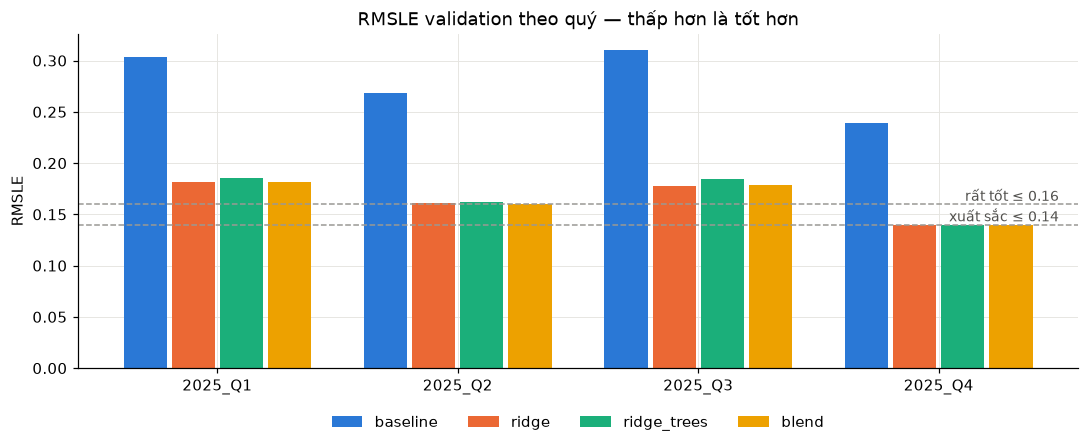

In [9]:
scores = cv_metrics.pivot(index='fold', columns='model', values='RMSLE')[MODELS]
fig, ax = plt.subplots(figsize=(10, 4.2))
width = 0.2
for i, (color, name) in enumerate(zip(COLORS, MODELS)):
    ax.bar(np.arange(len(scores)) + (i - 1.5) * width, scores[name], width * 0.9, color=color, label=name)
for level, label in [(0.16, 'rất tốt ≤ 0.16'), (0.14, 'xuất sắc ≤ 0.14')]:
    ax.axhline(level, color='#9a9994', linestyle='--', linewidth=1)
    ax.text(len(scores) - 0.5, level, label, va='bottom', ha='right', color='#52514e', fontsize=9)
ax.set_xticks(range(len(scores)), scores.index)
ax.set(title='RMSLE validation theo quý — thấp hơn là tốt hơn', ylabel='RMSLE')
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(OUT / 'validation_scores.png', bbox_inches='tight')
plt.show()

## 7. Phân tích lỗi

Lỗi của `blend` theo nhóm: loại cửa hàng, giai đoạn Tết, cửa hàng đã/chưa có lịch sử, khuyến mãi.
`error_analysis.csv` lưu toàn bộ bảng.

In [10]:
analysis = cv_predictions.merge(stores[['store_id', 'store_type']], on='store_id', validate='many_to_one')
offset = build_features(analysis).tet_offset.to_numpy()
analysis['tet_phase'] = np.select([offset < -14, offset < -3, offset <= 4, offset <= 14],
                                  ['ngoài Tết', 'trước Tết', 'lõi Tết', 'sau Tết'], 'ngoài Tết')

groups = [{'group': col, 'value': value, 'rows': len(d), **evaluate(d.revenue, d.blend)}
          for col in ['store_type', 'tet_phase', 'seen_store', 'is_promo']
          for value, d in analysis.groupby(col)]
error_table = pd.DataFrame(groups)[['group', 'value', 'rows', 'RMSLE', 'MAPE_%', 'Acc_20%', 'Bias_%']]
error_table.to_csv(OUT / 'error_analysis.csv', index=False)
display(error_table.round(3))

analysis['log_error'] = np.log1p(analysis.blend) - np.log1p(analysis.revenue)
print('10 ngày sai nhiều nhất (phần lớn là ngày đột biến không đoán trước được):')
display(analysis.reindex(analysis.log_error.abs().sort_values(ascending=False).index)
        .head(10)[['date', 'store_id', 'store_type', 'revenue', 'blend', 'log_error']].round(2))

,group,value,rows,RMSLE,MAPE_%,Acc_20%,Bias_%
0,store_type,mall,2312,0.171,11.296,86.678,2.351
1,store_type,office,3722,0.156,10.941,89.334,1.566
2,store_type,residential,1653,0.164,11.743,90.139,1.157
3,store_type,street,4972,0.173,10.384,88.274,0.749
4,store_type,university,1560,0.154,11.808,88.397,-0.359
5,tet_phase,lõi Tết,210,0.230,15.121,75.714,1.789
6,tet_phase,ngoài Tết,13265,0.161,10.796,89.001,1.002
7,tet_phase,sau Tết,357,0.249,14.479,80.112,4.038
8,tet_phase,trước Tết,387,0.171,12.267,86.822,3.144
9,seen_store,False,370,0.239,20.320,53.243,-3.096


10 ngày sai nhiều nhất (phần lớn là ngày đột biến không đoán trước được):


C:\Users\Ngoc Hieu\AppData\Local\Temp\ipykernel_22852\3362815248.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .head(10)[['date', 'store_id', 'store_type', 'revenue', 'blend', 'log_error']].round(2))


,date,store_id,store_type,revenue,blend,log_error
6681,2025-06-30,S25,street,372.0,27.04,-2.59
7900,2025-07-30,S32,university,120.4,9.52,-2.45
6228,2025-06-19,S16,street,262.7,21.97,-2.44
7366,2025-07-17,S26,office,257.6,21.54,-2.44
7374,2025-07-17,S34,street,250.8,21.48,-2.42
1051,2025-02-01,S43,street,225.0,19.28,-2.41
8157,2025-08-06,S08,street,239.8,22.22,-2.34
5272,2025-05-26,S20,residential,94.5,8.49,-2.31
4134,2025-04-26,S34,street,236.6,22.73,-2.30
10127,2025-09-24,S26,office,150.5,14.28,-2.29


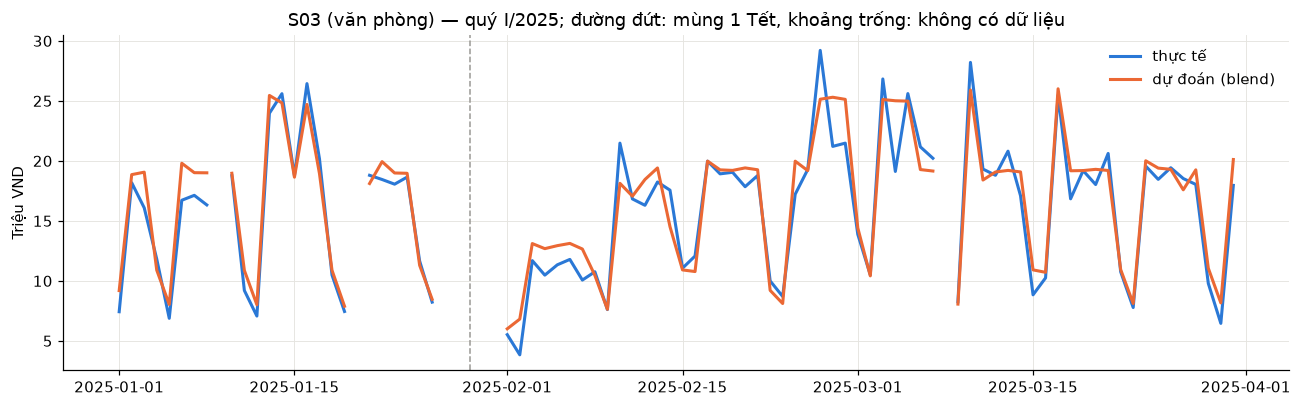

In [11]:
# asfreq('D') để trống những ngày cửa hàng không có dòng (đóng cửa dịp Tết) thay vì nối thẳng qua
example = (analysis[(analysis.fold == '2025_Q1') & (analysis.store_id == 'S03')]
           .set_index('date').sort_index()[['revenue', 'blend']].asfreq('D'))
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(example.index, example.revenue, color=COLORS[0], label='thực tế')
ax.plot(example.index, example.blend, color=COLORS[1], label='dự đoán (blend)')
ax.axvline(TET[1], color='#9a9994', linestyle='--', linewidth=1)
ax.set(title='S03 (văn phòng) — quý I/2025; đường đứt: mùng 1 Tết, khoảng trống: không có dữ liệu', ylabel='Triệu VND')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / 'example_store_q1.png', bbox_inches='tight')
plt.show()

## 8. Train trên toàn bộ dữ liệu và ghi 2 submission

Huấn luyện lại trên toàn bộ 2024–2025 (đủ 2 mùa Tết) rồi dự đoán `test.csv`.
Hai file để chọn làm final submission trên Kaggle:

- `submission_1_ridge.csv` — Ridge robust
- `submission_2_blend.csv` — 0.7 Ridge + 0.3 Ridge+Trees

Seed cố định nên chạy lại notebook cho ra đúng hai file này (yêu cầu tái tạo của môn học).

In [12]:
def save_submission(prediction, filename):
    result = pd.DataFrame({'id': test.id.to_numpy(), 'revenue': np.round(prediction, 4)})
    assert test.id.is_unique and sample.id.is_unique, 'id bị trùng'
    assert set(result.id) == set(sample.id), 'id của test.csv không khớp sample_submission.csv'
    assert np.isfinite(result.revenue).all() and (result.revenue >= 0).all(), 'dự đoán âm hoặc không hợp lệ'
    result = sample[['id']].merge(result, on='id', how='left', validate='one_to_one')
    result.to_csv(OUT / filename, index=False)
    print(f'Đã ghi {OUT / filename}: {result.shape}')
    return result


started = time.time()
predict_final = fit_models(X_all, y_all)
print(f'Train toàn bộ {len(y_all)} dòng: {time.time() - started:.0f}s')

if test is None:
    print('CHƯA CÓ test.csv — chạy notebook trên Kaggle (Add Input cuộc thi) để tạo submission.')
else:
    test_log = predict_final(build_features(test))
    submissions = {'submission_1_ridge.csv': np.expm1(test_log['ridge']),
                   'submission_2_blend.csv': np.expm1(test_log['blend'])}
    for filename, prediction in submissions.items():
        submission = save_submission(prediction, filename)
    display(submission.head())

Train toàn bộ 26500 dòng: 10s
CHƯA CÓ test.csv — chạy notebook trên Kaggle (Add Input cuộc thi) để tạo submission.


## 9. Gợi ý cho quyết định kinh doanh

Dự báo được gộp theo tháng và loại cửa hàng để lên kế hoạch nhân sự/nhập hàng, và so sánh tuần Tết với tuần bình thường.
Lưu ở `forecast_summary.csv`. Validation quý I/2025 cho thấy sai số tương đối cỡ RMSLE ~0.18,
tức nên chừa biên an toàn khoảng ±15–20% khi đặt hàng theo dự báo từng ngày.

In [13]:
if test is not None:
    forecast = test[['date', 'store_id']].assign(revenue=submissions['submission_2_blend.csv'])
    forecast = forecast.merge(stores[['store_id', 'store_type', 'city']], on='store_id', validate='many_to_one')
    forecast['month'] = forecast.date.dt.to_period('M').astype(str)
    by_month = forecast.pivot_table(index='store_type', columns='month', values='revenue', aggfunc='sum').round(0)
    by_month['Q1_total'] = by_month.sum(axis=1)
    display(by_month)
    by_month.to_csv(OUT / 'forecast_summary.csv')

    days_to_tet = (forecast.date - pd.Timestamp(TET[-1])).dt.days
    per_day = forecast.assign(phase=np.where(days_to_tet.between(-2, 3), 'tet', 'normal'))
    tet_effect = (per_day.groupby(['store_type', 'phase']).revenue.mean().unstack()
                  .reindex(columns=['tet', 'normal']).round(1))
    tet_effect['tet_vs_normal_%'] = (100 * (tet_effect.tet / tet_effect.normal - 1)).round(0)
    print('Doanh thu trung bình/ngày: lõi Tết (−2…+3) so với ngày khác')
    display(tet_effect)
else:
    print('Cần test.csv để tóm tắt dự báo.')

Cần test.csv để tóm tắt dự báo.


## File kết quả

| File | Nội dung |
|---|---|
| `data_quality.csv` | Số lượng từng loại lỗi dữ liệu |
| `train_clean.csv` | train sau khi bỏ trùng và sửa đơn vị |
| `cv_metrics_by_fold.csv` | Mọi chỉ số, theo từng quý × mô hình |
| `cv_metrics_summary.csv` | Trung bình 4 quý và gộp toàn bộ dòng validation |
| `cv_predictions.csv` | Thực tế và dự đoán của từng mô hình trên validation |
| `error_analysis.csv` | Lỗi theo loại cửa hàng / Tết / cửa hàng mới / khuyến mãi |
| `submission_1_ridge.csv`, `submission_2_blend.csv` | Hai file nộp Kaggle |
| `forecast_summary.csv` | Tổng doanh thu dự báo theo tháng × loại cửa hàng |

Điểm validation chỉ là ước lượng; điểm thật là private leaderboard sau hạn nộp.